# Header: Use gridded empymod to understand conductive anomaly behaviour

Goals:
- visualize the field around conductive anomalies of a certain thickness

# Code

In [1]:
import emg3d
import empymod
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm, Normalize
from Emg3d_extra_grid_functions_v26 import *

plt.style.use('bmh')

# Comment this out on Google Colab
#%matplotlib widget

## Functions

### Load empymod values to grid

Usually we use plot_slice to plot values, but this interpolates the output to cell centers (Ez values live on the edges).
To compare emg3d results with empymod I write a function that directly plots the results using matplotlib without interpolation.

Note: we can only use the inner domain where no cell stretching is taking place: y = [-300, 300], z = [-250, -5] & cell width is constant

In [2]:
def higher_or_lower(value1, value2):
    return (value2-value1)/np.abs(value1-value2)

In [3]:
def find_distance_1d(value1, coord_list):
    distances = []
    for value2 in coord_list:
        distances.append(np.abs(value1-value2))
    return np.argmin(distances)

To insert the empymod values into the grid we need to put the values in the right location.
Ez field values are saved on the vertical edges of the grid cells, calculated at the center of the cell
Therefore we need to calculate empymod results on the vertical edges of grid cells as well
So for each receiver the x,y coordinates are given by cell centers
And the z-coordinate is given by the cell edges

We replace values in a dummy grid in the locations inside the domain.
We make sure the values correspond to the correct cell, and then can fix domain issues later

In [4]:
normal_dict = {'X': [0, 1, 2], 'Y': [1, 0, 2], 'Z' : [1, 2, 0]}

def find_Ez_slice_corners(grid, normal = 'X', slice_loc = 0, range_x=[-300, 300], range_y=[-300, 25]):

    # We need to understand where to take the slice in x,y,z coordinates
    arg_locs = [[slice_loc, slice_loc], range_x, range_y]
    arg_to_xyz = normal_dict[normal]
    x_min, y_min, z_min = arg_locs[arg_to_xyz[0]][0], arg_locs[arg_to_xyz[1]][0], arg_locs[arg_to_xyz[2]][0]
    x_max, y_max, z_max = arg_locs[arg_to_xyz[0]][1], arg_locs[arg_to_xyz[1]][1], arg_locs[arg_to_xyz[2]][1]

    # Now we locate the indeces of the required cells in the grid, noting that we acquire the Ez field values on the vertical edges
    ix_min = find_distance_1d(x_min, grid.nodes_x)
    ix_max = find_distance_1d(x_max, grid.nodes_x)
    iy_min = find_distance_1d(y_min, grid.nodes_y)
    iy_max = find_distance_1d(y_max, grid.nodes_y)
    iz_min = find_distance_1d(z_min, grid.cell_centers_z)
    iz_max = find_distance_1d(z_max, grid.cell_centers_z)

    return [ix_min, ix_max, iy_min, iy_max, iz_min, iz_max]

In [5]:
def find_Ez_slice_locs(grid, i_corners):
    
    x_locs = []
    y_locs = []
    z_locs = []
    for ix in np.arange(i_corners[0], i_corners[1]+1):
        x_locs.append(grid.nodes_x[ix])
    for iy in np.arange(i_corners[2], i_corners[3]+1):
        y_locs.append(grid.nodes_y[iy])
    for iz in np.arange(i_corners[4], i_corners[5]+1):
        z_locs.append(grid.cell_centers_z[iz])

    return [x_locs, y_locs, z_locs]

In [6]:
normal_dict2 = {'X' : [0, 1, 2], 'Y' : [1, 0, 2], 'Z' : [2, 0, 1]}

def empymod_domain(xyz_locs, inp, normal = 'X'):
        #when normal is 'X' I want to use all the y-coordinates at once

        responses = np.zeros((len(xyz_locs[0]), len(xyz_locs[1]), len(xyz_locs[2])), dtype=complex)
        len_range_y = len(xyz_locs[normal_dict2[str(normal)][2]])

        #Two of these should use only the first index, the normal and one other
        for i in np.arange(len_range_y):
            if normal == 'X':
                receivers = [xyz_locs[0][0], xyz_locs[1], xyz_locs[2][i], 0, 90]
                responses[0,:,i] = empymod.bipole(rec = receivers, **inp)
            elif normal == 'Y':
                receivers = [xyz_locs[0], xyz_locs[1][0], xyz_locs[2][i], 0, 90]
                responses[:,0,i] = empymod.bipole(rec = receivers, **inp)
            elif normal == 'Y':
                receivers = [xyz_locs[0], xyz_locs[1][i], xyz_locs[2][0], 0, 90]
                responses[:,i,0] = empymod.bipole(rec = receivers, **inp)

        return responses

In [7]:
def empymod_to_grid(grid, inp, normal = 'X', slice_loc = 0, range_x=[-300, 300], range_y=[-300, 25]):

    #Insert 0 values into grid, we assume we are computing Ez values
    grid_values = np.zeros((grid.shape_nodes[0], grid.shape_nodes[1], grid.shape_cells[2]), dtype=complex)

    #Find corner indeces
    i_corners = find_Ez_slice_corners(grid, normal, slice_loc, range_x, range_y)
    print(i_corners)

    # Find receiver locations to compute
    xyz_locs = find_Ez_slice_locs(grid, i_corners)

    #Compute responses for the receiver locations
    responses = empymod_domain(xyz_locs, inp, normal)

    #Insert into grid
    grid_values[i_corners[0]:i_corners[1]+1, i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1] = responses

    return grid_values, i_corners, xyz_locs

## Construct survey, grid and baseline model

In [72]:
# Source
source = [0, -126, 0, 90.0, 0] # y-directed point dipole on the surface

# Source frequency
frequency = 1

# Receiver offsets
offsets = np.arange(0, 300, 7.5)  # 300 m long receiver line

# receiver-array: x, y, z, azimuth, dip
receivers = (offsets*0, [74]*len(offsets), -offsets, 0, 90)  # z-directed, Ez response

# Layer boundaries
# We idealize the depth model here a bit, to have cells of 10m in depth
depth = [0, -50, -80, -120, -190]
depth2 = [0, -50, -80, -90, -99, -120, -190]

# Layer resistivities in Ohm.m for the baseline
resistivities_base = np.array([1e8, 52.0, 38.0, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)
resistivities_target = np.array([1e8, 52.0, 38.0, 26.0, 13, 26.0, 29.5, 17.5]) # base incl. air (lower res, because of 3D modelling)


In [73]:
grid = emg3d.construct_mesh(
    center=(0,-135,0),                                 # Center of wanted grid
    frequency=frequency,                            # Frequency we will use the grid for
    properties=[25, 1e8],                           # Reference resistivity
    domain=([-100, 100], [-140, 75], [-300, 25]),   # Domain in which we want precise results
    center_on_edge=True,
    min_width_limits = [5, 5, 1],
)
 
grid  # mesh info
#grid.plot_grid() # plotting the grid

TensorMesh: 3,538,944 cells

                      MESH EXTENT             CELL WIDTH      FACTOR
  dir    nC        min           max         min       max      max
  ---   ---  ---------------------------  ------------------  ------
   x     96   -100,983.68    100,983.68      5.00 26,632.29    1.36
   y     96   -108,515.59    151,698.35      5.00 43,247.76    1.40
   z    384   -105,222.79    149,991.84      1.00 45,044.04    1.43

## Empymod simulations

In [74]:
# define the input that stays the same for all models
inp = {
    'src': source,
    'depth': depth,
    'freqtime': frequency,
    'srcpts': 5,  # Models the finite-length source as 5 point sources with Gaussian Quadrature
    'htarg': {'pts_per_dec': -1},  # Faster computation
    'verb': 1,
    'strength': 1,
}

In [75]:
inp['res'] = resistivities_base
empymod_efield, i_corners, xyz_locs = empymod_to_grid(grid, inp, normal = 'X', slice_loc = 0, range_x=[-750, 750], range_y=[-500, 500])

[48, 48, 15, 80, 17, 367]


In [76]:
inp['res'] = resistivities_target
inp['depth'] = depth2
empymod_efield2, i_corners, xyz_locs = empymod_to_grid(grid, inp, normal = 'X', slice_loc = 0, range_x=[-750, 750], range_y=[-500, 500])

[48, 48, 15, 80, 17, 367]


### Taking the difference

In [77]:
# Take difference for all cells and save in an array ready to plot

difference = np.zeros_like(empymod_efield)
for ix in np.arange(i_corners[0], i_corners[1]+1):
    for iy in np.arange(i_corners[2], i_corners[3]+1):
        for iz in np.arange(i_corners[4], i_corners[5]+1):
            difference[ix, iy, iz] = empymod_efield2[ix, iy, iz] - empymod_efield[ix, iy, iz]

In [78]:
# Also calculate the percentage error

rel_error = np.zeros_like(empymod_efield)
for ix in np.arange(i_corners[0], i_corners[1]+1):
    for iy in np.arange(i_corners[2], i_corners[3]+1):
        for iz in np.arange(i_corners[4], i_corners[5]+1):
            rel_error[ix, iy, iz] = difference[ix, iy, ix]/empymod_efield[ix, iy, iz]

### Plots

Text(0.5, 0.98, 'Difference in efield for a small 1d anomaly')

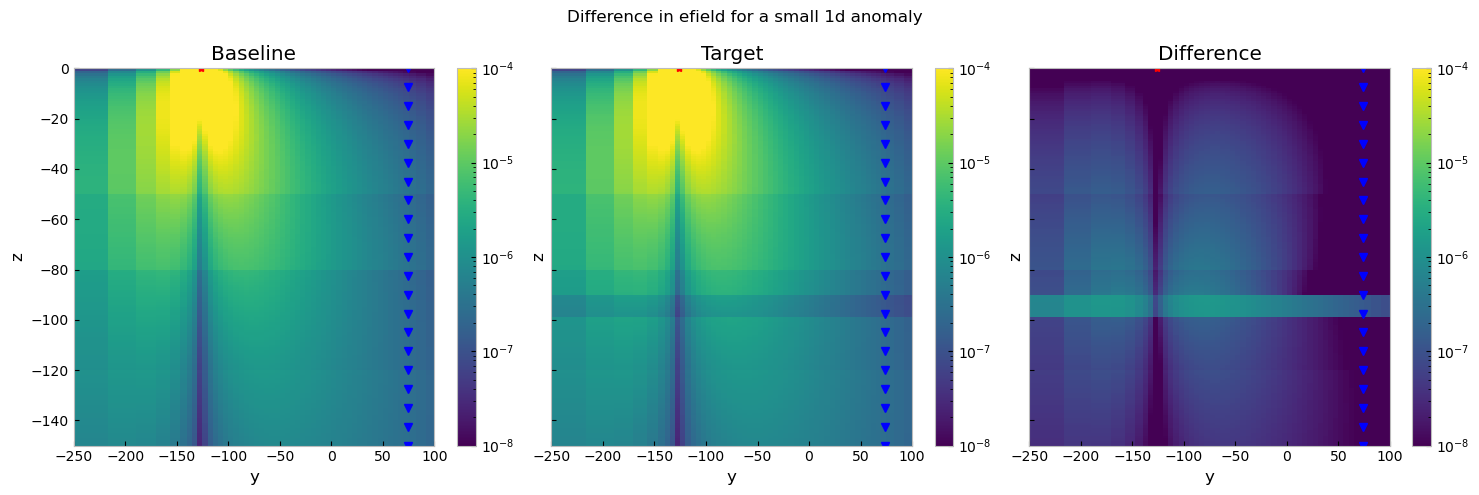

In [79]:
#Plot next to each other

vmin = 1e-8
vmax = 1e-4

popts = {'cmap': 'viridis', 'norm': LogNorm(vmin=vmin, vmax=vmax)}
opts = {'v_type': 'Ez', 'view': 'abs', 'normal': 'X', 'range_x': [-250, 100], 'range_y': [-150, 0]}

fig, axs = plt.subplots(1, 3, figsize = (15, 5), tight_layout=True, sharex = True, sharey = True)

to_plot = [empymod_efield.ravel('F'), empymod_efield2.ravel('F'), difference.ravel('F')]
titles = ['Baseline', 'Target', 'Difference']

for i in np.arange(3):
    # Plotting the fields
    f0 = grid.plot_slice(to_plot[i], ax=axs[i], pcolor_opts=popts, **opts)
    axs[i].set_title(titles[i])
    axs[i].plot(receivers[1], receivers[2], 'bv')
    axs[i].plot(source[1], source[2], 'r*')
    axs[i].grid(False)
    plt.colorbar(f0[0], ax=axs[i])#, fraction=.5, shrink=.8, aspect=30)

fig.suptitle('Difference in efield for a small 1d anomaly')


In [435]:
print(np.shape(rel_error[i_corners[0],i_corners[2]:i_corners[3]+1,i_corners[4]:i_corners[5]+1]))
print(np.shape(xyz_locs[1]))
print(np.shape(xyz_locs[2]))

(66, 155)
(66,)
(155,)


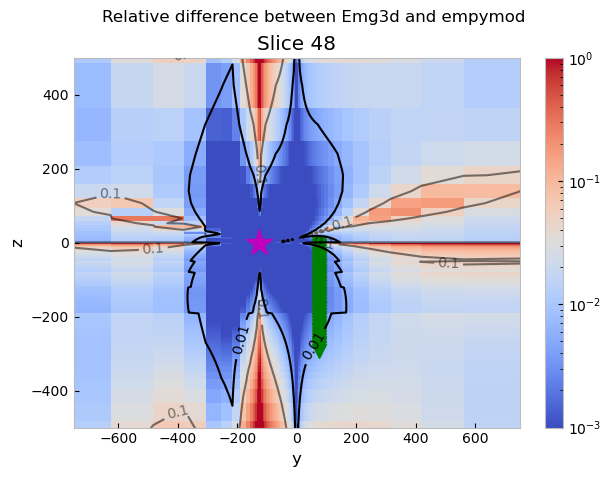

In [436]:
#Plot in the entire domain

#Focus on the y,z plane
f0 = grid.plot_slice(
    rel_error.ravel('F'),
    view = 'abs',
    v_type = 'Ez',
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1e-3, vmax=1), 'cmap': 'coolwarm'},
    range_x=[-750, 750],
    range_y=[-500, 500],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Relative difference between Emg3d and empymod')
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'gv', markersize = 10)
axs[1].plot(source[1], source[2], 'm*', markersize = 20)
axs[1].grid(False)

# Add contour at relative error = 0.1
c1 = axs[1].contour(xyz_locs[1], xyz_locs[2], np.transpose(np.abs(rel_error[i_corners[0],i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1])), levels=[0.01] ,colors=('k', 1), linewidths=1.5)
c2 = axs[1].contour(xyz_locs[1], xyz_locs[2], np.transpose(np.abs(rel_error[i_corners[0],i_corners[2]:i_corners[3]+1, i_corners[4]:i_corners[5]+1])), levels=[0.1] ,colors=('k', 0.5), linewidths=1.5)

axs[1].clabel(c1, inline=True, fontsize=10, fmt='%.2f')
axs[1].clabel(c2, inline=True, fontsize=10, fmt='%.1f')

fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

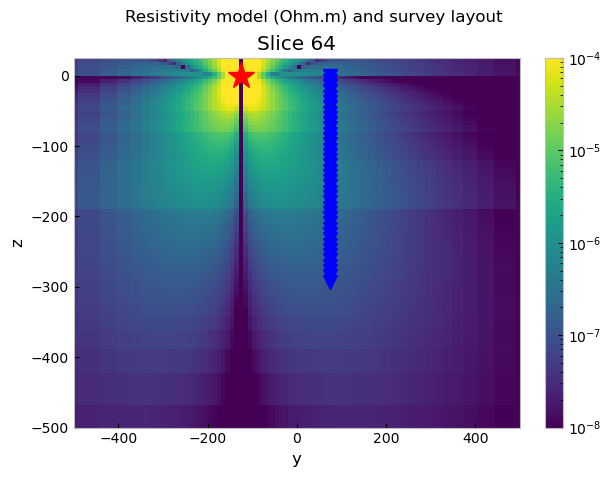

In [213]:
#Plot in the entire domain

#Focus on the y,z plane
f0 = grid.plot_slice(
    efield3D_base.fz.ravel('F'),
    view = 'abs',
    v_type = 'Ez',
    normal = 'X',
    pcolor_opts={'norm': LogNorm(vmin=1e-8, vmax=1e-4)},
    range_x=[-500, 500],
    range_y=[-500, 25],
#    slice_loc=0
)
fig = plt.gcf()
fig.suptitle('Resistivity model (Ohm.m) and survey layout')
axs = fig.get_children()
axs[1].plot(receivers[1], receivers[2], 'bv', markersize = 10)
axs[1].plot(source[1], source[2], 'r*', markersize = 20)
axs[1].grid(False)
fig.colorbar(f0[0], ax=axs[1], fraction=0.05, location='right')

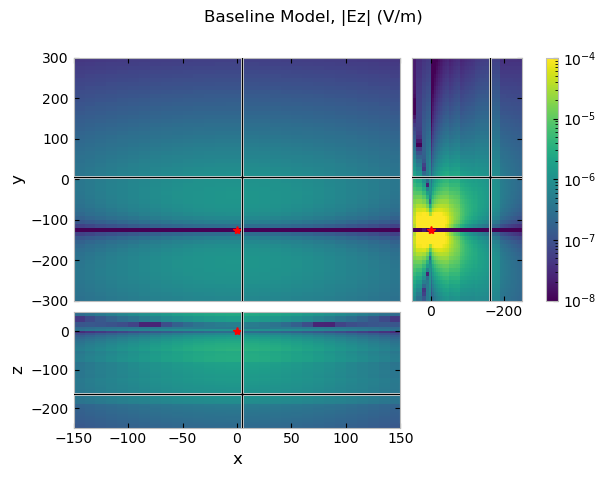

In [ ]:
#Plot in the inner domain

grid.plot_3d_slicer(
    efield3D_base.fz.ravel('F'),
    view='abs',
    v_type='Ez',
    pcolor_opts={'norm': LogNorm(vmin=1e-8, vmax=1e-4)},
    xlim=[-150, 150],
    ylim=[-300, 300],
    zlim=[-250, 50],
    zslice=-160,
)
# Plot survey in figure above
fig = plt.gcf()
fig.suptitle('Baseline Model, |Ez| (V/m)')
axs = fig.get_children()
rec_coords = receivers
src_coords = source
axs[1].plot(src_coords[0], src_coords[1], 'r*')
axs[2].plot(src_coords[0], src_coords[2], 'r*')
axs[3].plot(src_coords[2], src_coords[1], 'r*')
axs[1].grid(False)
axs[2].grid(False)
axs[3].grid(False)

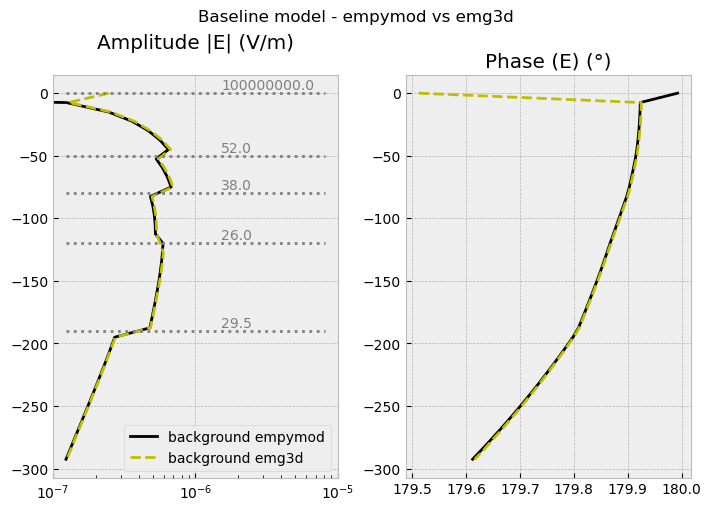

In [ ]:
# Plot receiver line responses
fig3, (ax31, ax32) = plt.subplots(1, 2, figsize=(7, 5), constrained_layout=True)

fig3.suptitle("Baseline model - empymod vs emg3d")

ax31.set_title('Amplitude |E| (V/m)')
ax31.plot(resp_E_base.amp(), -offsets, 'k', label='background empymod')
ax31.plot(resp_E_base_3D.amp(), -offsets, 'y--', label='background emg3d') # scale your emg3d amplitues by the source length
ax31.set_xscale('log')
ax31.set_xlim([1e-7, 1e-5])
ax31.legend()

ax32.set_title('Phase (E) (°)')
ax32.plot(resp_E_base.pha(deg=True), -offsets, 'k')
ax32.plot(resp_E_base_3D.pha(deg=True), -offsets, 'y--')

ax33 = ax31.twiny()
#ax33.set_title('Model rho (Ohmm)')
#ax33.plot([75, 52.0, 52.0, 38.0, 38.0, 26.0, 26.0, 29.5, 29.5, 17.5, 17.5], [0, 0, -50, -50, -80, -80, -120, -120, -190, -190, -300], 'gray', ls='-')
ax33.hlines(depth, 0, 1, color='gray', ls=':', zorder=-1)
for i in np.arange(len(depth)):
    ax33.text(0.6, depth[i]+3, str(resistivities_base[i]), color='gray')
ax33.set_axis_off()

In [ ]:
#plot to add: emg3d vs. empymod + difference

efield1 = crop_to_domain(efield3D_base, grid, x_slice = 0, y_extent=300, zmin=-250, zmax=0)
efield2 = Ez_Empy_base
efield3 = np.abs(efield2)-np.abs(efield1)

manual_plot_slice_3x(efield1, efield2, efield3, y_extent=300, zmin=-250, zmax=0, size_y = 6.4, size_z = 4.8, vmin = 1e-8, vmax = 1e-3)

NameError: name 'efield3D_base' is not defined